## **Configuraciones de Amplificadores Operacionales**

En este notebook se construyen las configuraciones básicas del amplificador operacional utilizando **lcapy**:

* Amplificador inversor
* Amplificador no inversor
* Sumador inversor de dos entradas
* Amplificador diferencial
* Diferenciador
* Integrador

Para cada configuración se dibuja el esquema, se obtiene la **función de transferencia** (salida vs. entrada) con ganancia finita $A$ y se toma el **límite ideal** $A \to \infty$. 

In [57]:
#librerias necesarias para el notebook
from lcapy import Circuit, t, pi, omega0
from lcapy import s, j, exp, cos, sin, sqrt
from sympy import oo
import sympy as sy
import matplotlib.pyplot as plt

### *El modelo del amplificador operacional en Lcapy*

Un amplificador operacional se modela en Lcapy como una **fuente de tensión controlada por tensión (VCVS)** mediante la componente `E` con la palabra clave `opamp`:

```
E out gnd opamp in+ in- A
```

donde:

* `out` y `gnd` son los nodos de salida (el modelo de Lcapy tiene una salida **diferencial**: el nodo inferior se conecta a tierra con un alambre).
* `in+` e `in-` son los nodos de las entradas no inversora e inversora.
* `A` es la **ganancia de lazo abierto** (símbolo). La tensión de salida es
  $v_o = A\,(v_+ - v_-)$.

El atributo `mirror` (o `flipud`) intercambia la posición de las entradas $+$ y $-$ en el esquema dibujado.

La estrategia de análisis es siempre la misma:

1. Se construye el circuito con `Circuit(...)` usando puertos `P1` (entrada) y `P2` (salida).
2. Se calcula la función de transferencia con `Pn.transfer('Pm')`.
3. Se toma el **límite ideal** con $A \to \infty$: `.limit('A', oo)`.
4. Las impedancias se obtienen con `cct.impedance('Pn')`, igual que en la etapa CS.

## **Amplificador inversor**

La entrada $v_1$ se aplica a través de $R_1$ a la entrada inversora ($-$). La entrada no inversora ($+$) se conecta a tierra y $R_2$ cierra la realimentación desde la salida hacia la entrada inversora.

Con el modelo VCVS de ganancia finita $A$ el circuito es realimentado y Lcapy lo resuelve exactamente. Para ganancias grandes el límite $A \to \infty$ da la ganancia de lazo cerrado:

$$H = \frac{v_o}{v_i} = -\frac{R_2}{R_1}$$

La ganancia es independiente de $A$ mientras $A \gg R_2/R_1$. El signo menos indica la inversión de fase.

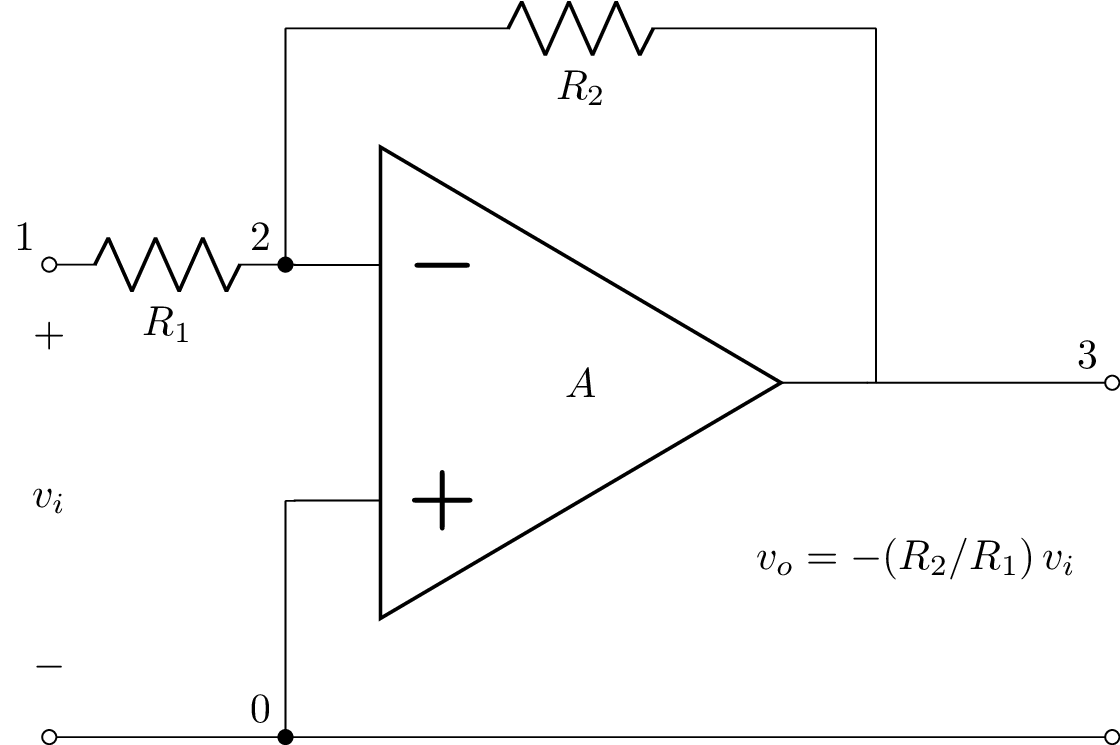

In [58]:
#AMPLIFICADOR INVERSOR
inv = Circuit("""
                P1 1 0_1; down, v_=v_i
                R1 1 2; right
                R2 2_1 3_1; right
                E1 3_2 0_3 opamp 2_0 2 A; mirror
                W 0_1 0; right
                W 2_0 0; down
                W 3_2 3; right
                W 0 0_3; right
                P2 3 0_3; down, v^=, l={v_o = -(R_2/R_1)\\,v_i}
                W 2_1 2; down
                W 3_1 3_2; down
            """)
inv.draw()

### *Función de transferencia*

In [59]:
#FUNCION DE TRANSFERENCIA (con ganancia finita A)
H_inv = inv.P1.transfer('P2')


In [60]:
#GANANCIA EN EL LIMITE IDEAL A -> infinito
H_inv_ideal = H_inv.limit('A', oo).simplify()
H_inv_ideal

-R₂ 
────
 R₁ 

## **Amplificador no inversor**

La entrada $v_i$ se aplica directamente a la entrada no inversora ($+$). El divisor resistivo $R_1$–$R_2$ (con $R_1$ a tierra y $R_2$ hasta la salida) muestrea la salida y la devuelve a la entrada inversora ($-$).

En el límite ideal la ganancia de lazo cerrado es siempre mayor que 1:

$$H = \frac{v_o}{v_i} = 1 + \frac{R_2}{R_1}$$


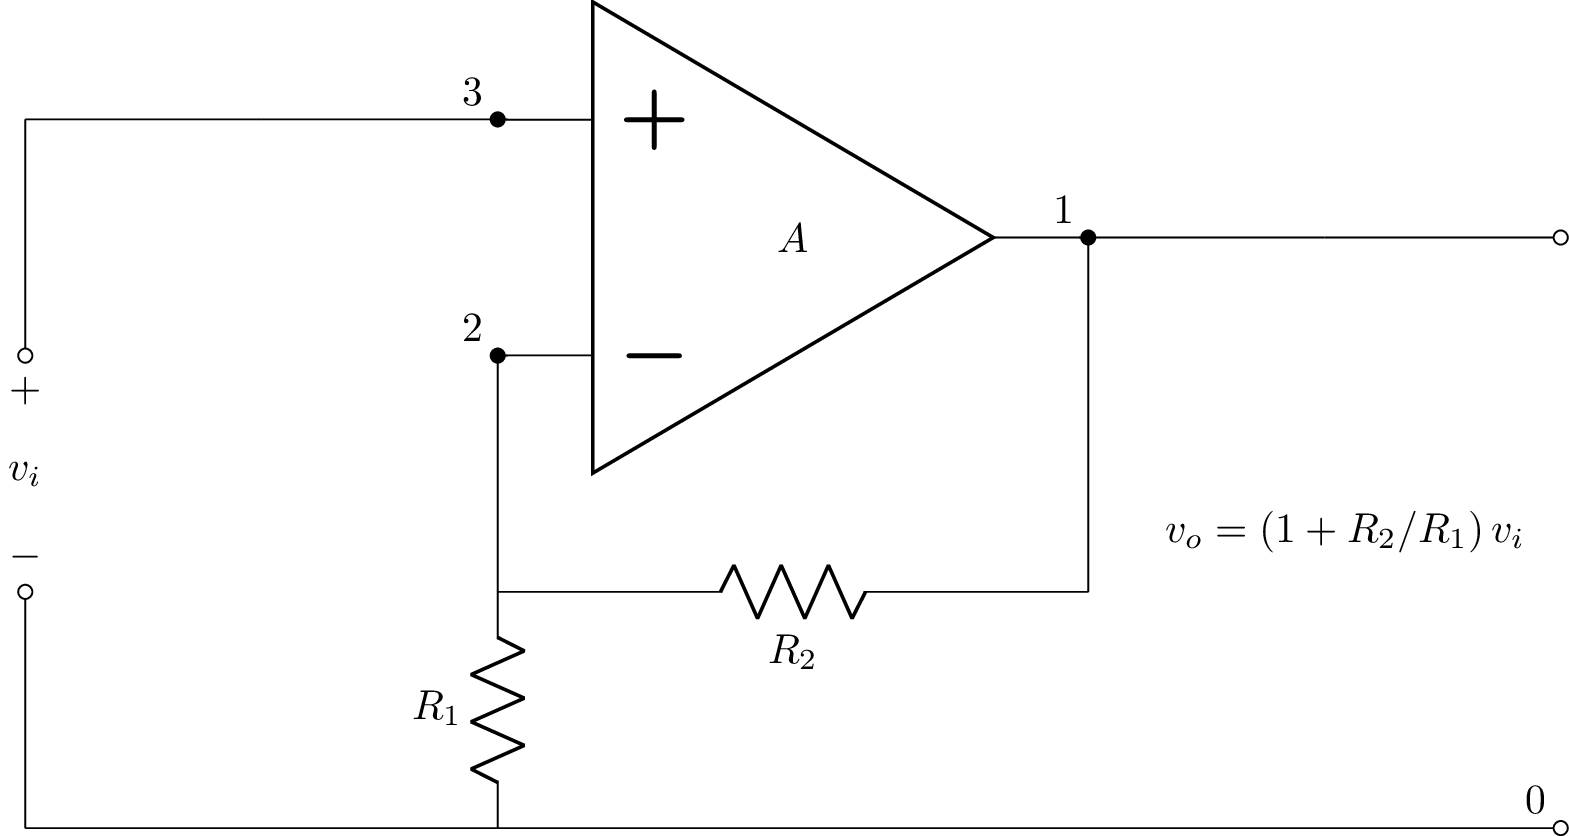

In [61]:
#AMPLIFICADOR NO INVERSOR
noninv = Circuit("""
                P1 3_2 0_3; down, v_=v_i
                R1 2_1 0_2 R1; down
                R2 2_1 1_1 R2; right
                E 1 0 opamp 3 2 A; right
                W 2 2_1; down
                W 1 1_1; down
                W 3_1 3_2; down
                W 0_3 0_1; down
                W 3_1 3_3; right
                W 3_3 3; right
                W 1 1_2; right
                W 1_2 1_3; right
                P2 1_3 0; down, v^=, l={v_o = (1 + R_2/R_1)\\,v_i}
                W 0_1 0_2; right
                W 0_2 0; right
            """)
noninv.draw()

### *Función de transferencia*

In [62]:
#FUNCION DE TRANSFERENCIA (con ganancia finita A)
H_noninv = noninv.P1.transfer('P2')


In [63]:
#GANANCIA EN EL LIMITE IDEAL A -> infinito
H_noninv_ideal = H_noninv.limit('A', oo).simplify()
H_noninv_ideal

R₁ + R₂
───────
  R₁   

## **Sumador inversor**

Dos fuentes $v_a$ y $v_b$ se suman en el nodo inversor a través de $R_1$ y $R_{1b}$. El nodo $-$ es un **nodo de masa virtual** y cada resistencia aporta su propia corriente en forma independiente. La salida es la suma con signo invertido:

$$v_o = \left(- \frac{R_2}{R_1}\right)(v_a + v_b) $$

Lcapy lo confirma midiendo la transferencia desde cada puerto por separado (la otra entrada queda abierta, pero como el nodo $-$ es masa virtual).

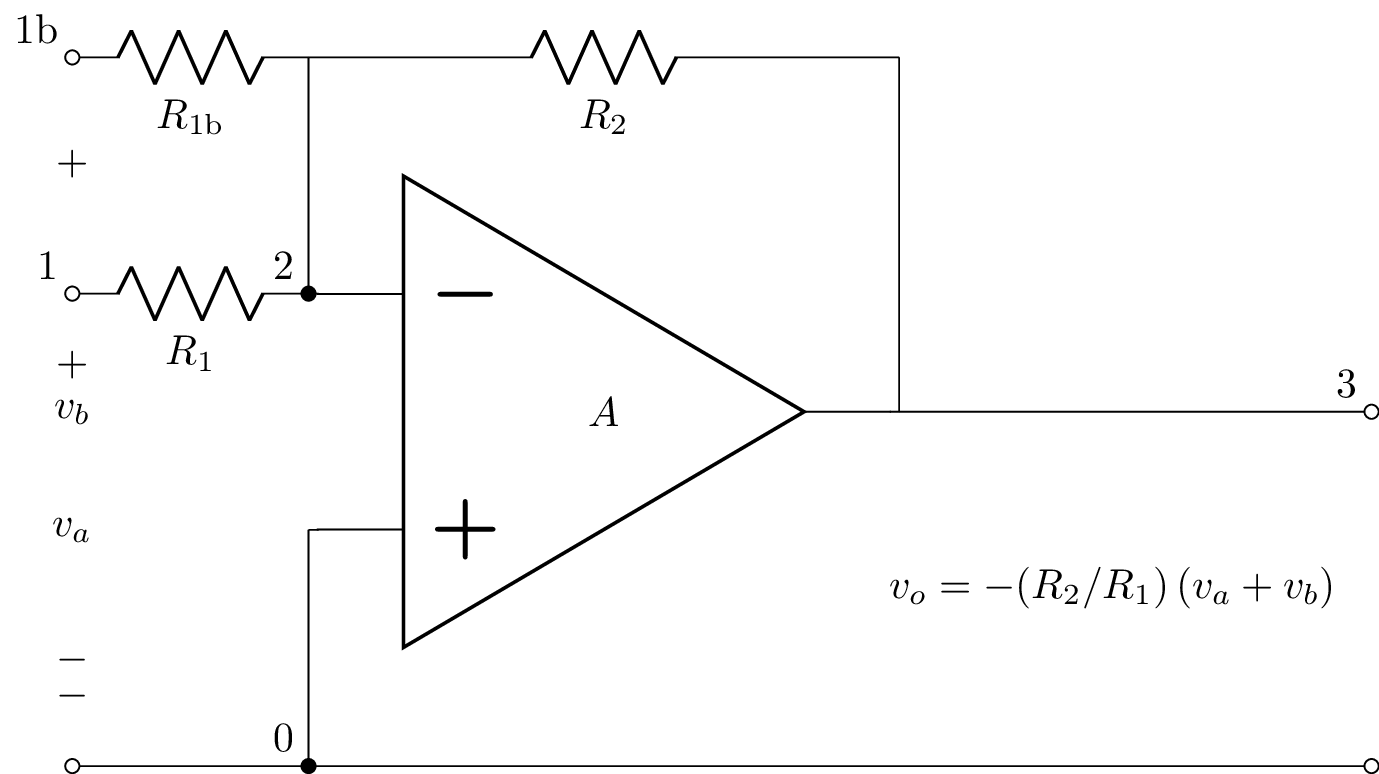

In [64]:
#SUMADOR INVERSOR (2 entradas)
suma = Circuit("""
                P1 1 0_1; down, v_=v_a
                P1b 1b 0_1; down=2.5, v_=v_b
                R1 1 2; right
                R1b 1b 2_1; right
                R2 2_1 3_1; right
                E1 3_2 0_3 opamp 2_0 2 A; mirror
                W 0_1 0; right
                W 2_0 0; down
                W 3_2 3; right=2
                W 0 0_3; right
                P2 3 0_3; down, v^=, l={v_o = -(R_2/R_1)\\,(v_a + v_b)}
                W 2_1 2; down
                W 3_1 3_2; down
            """)
suma.draw()

### *Función de transferencia*

In [65]:
#TRANSFERENCIA DESDE LA ENTRADA a (P1)
H_sum_a = suma.P1.transfer('P2').limit('A', oo).simplify()
H_sum_a

-R₂ 
────
 R₁ 

In [66]:
#TRANSFERENCIA DESDE LA ENTRADA b (P1b)
H_sum_b = suma.P1b.transfer('P2').limit('A', oo).simplify()
H_sum_b

-R₂ 
────
R_1b

In [67]:
#SALIDA TOTAL (superposicion): v2 = -(R2/R1) va - (R2/R1b) vb
va, vb = sy.symbols('v_a v_b')
H_sum_a*va + H_sum_b*vb

  R₂⋅v_b   R₂⋅vₐ
- ────── - ─────
   R_1b     R₁  

## **Amplificador diferencial**

La entrada $v_a$ entra por la rama inversora a través de $R_1$, y la entrada $v_b$ entra por la rama no inversora a través del divisor $R_{b1}$–$R_{b2}$.

Al medir la transferencia desde **un solo puerto** con el otro abierto, el circuito no se comporta como en operación: por ejemplo, desde $P_{1b}$ (con $P_1$ abierta) Lcapy devuelve el divisor de tensión $R_{b2}/(R_{b1}+R_{b2})$, porque sin corriente por $R_1$ no hay realimentación efectiva. La forma correcta de analizar es con **las dos entradas excitadas**, para lo cual se arma una copia del circuito con fuentes de tensión simbólicas `va` y `vb`.

Con resistencias igualadas ($R_1 = R_2 = R_f$ y $R_{b1} = R_{b2} = R_c$) se obtiene el resultado clásico:

$$v_o = v_b - v_a$$

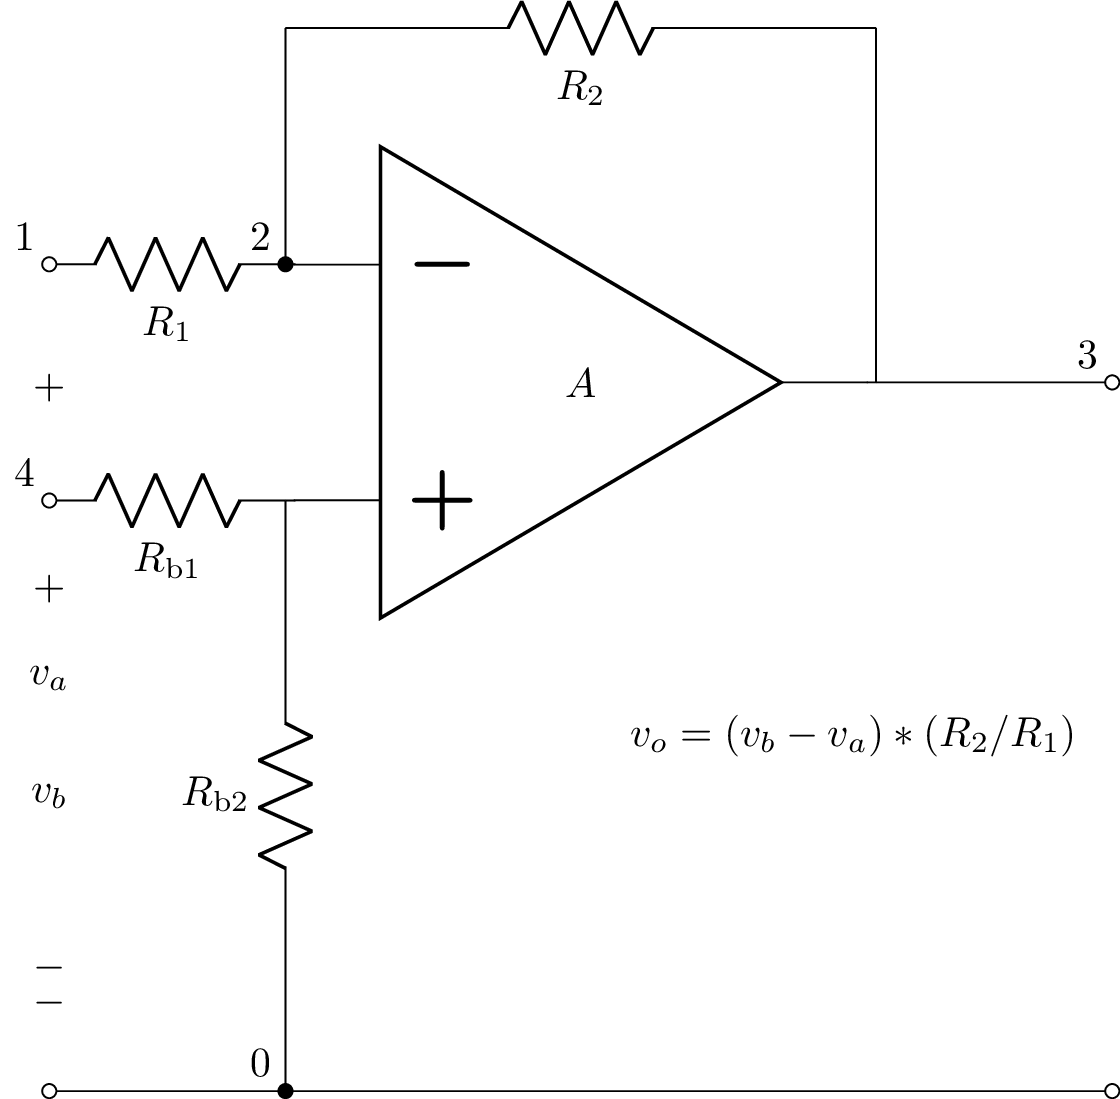

In [68]:
#AMPLIFICADOR DIFERENCIAL
rest = Circuit("""
                P1b 4 0_1; down=2.5, v_=v_b
                Rb1 4 2_0; right
                Rb2 2_0 0; down
                P1 1 0_1; down, v_=v_a
                R1 1 2; right
                R2 2_1 3_1; right
                E1 3_2 0_3 opamp 2_0 2 A; mirror
                W 2_1 2; down
                W 3_1 3_2; down
                W 3_2 3; right
                W 0 0_3; right
                P2 3 0_3; down, v^=, l={v_o = (v_b - v_a)*(R_2/R_1)}
                W 0_1 0; right
            """)
rest.draw()

### *Función de transferencia*

In [69]:
#TRANSFERENCIA DESDE LA ENTRADA INVERSORA (P1, con el divisor Rb1-Rb2 presente)
H_rest_a = rest.P1.transfer('P2').limit('A', oo).simplify()
H_rest_a

-R₂ 
────
 R₁ 

In [70]:
#ANALISIS POR SUPERPOSICION CON LAS DOS ENTRADAS SIMBOLICAS
rest_dc = Circuit("""
                Vb 4 0_1 dc vb; down=2.5
                Rb1 4 2_0; right
                Rb2 2_0 0; down
                Va 1 0_1 dc va; down
                R1 1 2; right
                R2 2_1 3_1; right
                E1 3_2 0_3 opamp 2_0 2 A; mirror
                W 2_1 2; down
                W 3_1 3_2; down
                W 3_2 3; right
                W 0 0_3; right
                W 0_1 0; right
            """)
Vout = rest_dc[3].V.dc
Vout_ideal = Vout.limit('A', oo).simplify()
Vout_ideal

R₁⋅R_b2⋅v_b - R₂⋅R_b1⋅vₐ - R₂⋅R_b2⋅vₐ + R₂⋅R_b2⋅v_b
───────────────────────────────────────────────────
                 R₁⋅(R_b1 + R_b2)                  

In [71]:
#CASO DE RESISTENCIAS IGUALADAS: R1 = R2 = R_f y Rb1 = Rb2 = R_c
R_f = sy.Symbol('R_f', positive=True)
R_c = sy.Symbol('R_c', positive=True)
Vout_ideal.subs({'R1': R_f, 'R2': R_f, 'Rb1': R_c, 'Rb2': R_c}).simplify()

-vₐ + v_b

## **Diferenciador**

La entrada $v_1$ se acopla a la entrada inversora a través del capacitor $C_1$ y $R_2$ cierra la realimentación. El capacitor bloquea la componente continua y su admitancia crece con la frecuencia, de modo que la salida es proporcional a la **derivada** de la entrada:

$$V_o(s) = -R_2\,C_1\,s\;V_i(s) \quad\Longleftrightarrow\quad v_o = -R_2\,C_1\,\frac{dv_i}{dt}$$

Para observar el comportamiento en el tiempo se puede excitar el circuito con una fuente y evaluar la tensión de salida correspondiente.

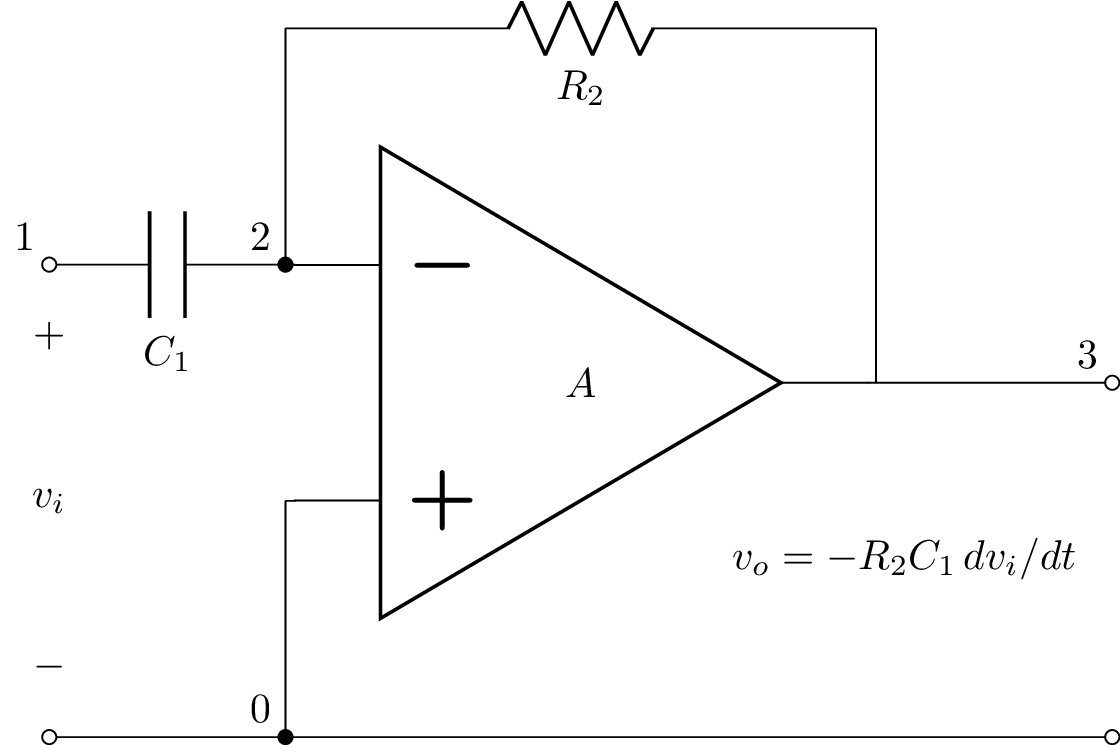

In [72]:
#DIFERENCIADOR
dif = Circuit("""
                P1 1 0_1; down, v_=v_i
                C1 1 2; right
                R2 2_1 3_1; right
                E1 3_2 0_3 opamp 2_0 2 A; mirror
                W 0_1 0; right
                W 2_0 0; down
                W 3_2 3; right
                W 0 0_3; right
                P2 3 0_3; down, v^=, l={v_o = -R_2 C_1\\,dv_i/dt}
                W 2_1 2; down
                W 3_1 3_2; down
            """)
dif.draw()

### *Función de transferencia*

In [73]:
#FUNCION DE TRANSFERENCIA EN s (con ganancia finita A)
H_dif = dif.P1.transfer('P2')
H_dif

  -A⋅s     
─────────⋅1
    A + 1  
s + ─────  
    C₁⋅R₂  

In [74]:
#GANANCIA EN EL LIMITE IDEAL A -> infinito
H_dif_ideal = H_dif.limit('A', oo).simplify()
H_dif_ideal

-C₁⋅R₂⋅s

## **Integrador**

Ahora el resistor $R_1$ está en la entrada y el capacitor $C_2$ en la realimentación. La corriente de la masa virtual carga a $C_2$ de modo que la tensión de salida es proporcional a la **integral** de la entrada:

$$V_o(s) = -\frac{1}{R_1\,C_2\,s}\;V_i(s) \quad\Longleftrightarrow\quad vo = -\frac{1}{R_1\,C_2}\int v_i \, dt$$

Tiene un polo en el origen (ganancia infinita en DC), lo que lo hace sensible a las tensiones de offset del opamp real.

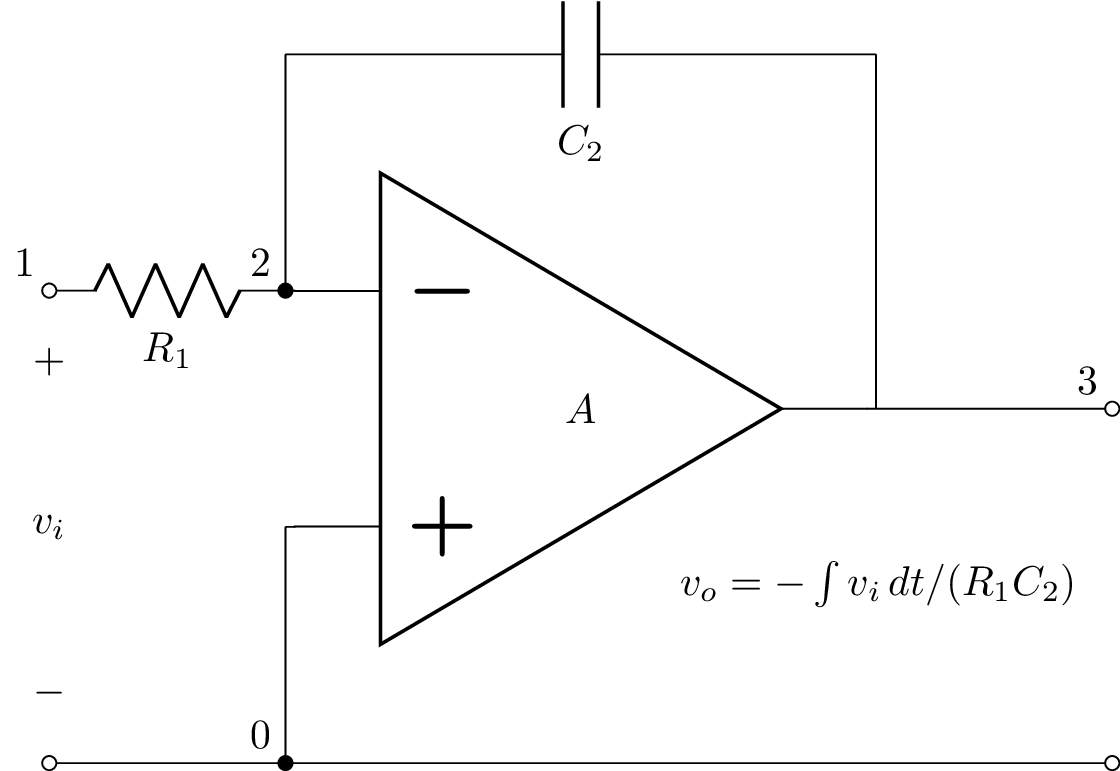

In [75]:
#INTEGRADOR
integ = Circuit("""
                P1 1 0_1; down, v_=v_i
                R1 1 2; right
                C2 2_1 3_1; right
                E1 3_2 0_3 opamp 2_0 2 A; mirror
                W 0_1 0; right
                W 2_0 0; down
                W 3_2 3; right
                W 0 0_3; right
                P2 3 0_3; down, v^=, l={v_o = -\\int v_i\\,dt/(R_1 C_2)}
                W 2_1 2; down
                W 3_1 3_2; down
            """)
integ.draw()

### *Función de transferencia*

In [76]:
#FUNCION DE TRANSFERENCIA EN s (con ganancia finita A)
H_int = integ.P1.transfer('P2')
H_int

  ⎛     -A      ⎞    
  ⎜─────────────⎟    
  ⎝C₂⋅R₁⋅(A + 1)⎠    
───────────────────⋅1
           1         
s + ───────────────  
    A⋅C₂⋅R₁ + C₂⋅R₁  

In [77]:
#GANANCIA EN EL LIMITE IDEAL A -> infinito
H_int_ideal = H_int.limit('A', oo).simplify()
H_int_ideal

  -1   
───────
C₂⋅R₁⋅s

### *Ejemplo con un circuito realimentado resuelto*

Finalmente se arma el amplificador inversor con los valores numéricos ($v_a = 0.5$ V, $R_1 = 1\,\text{k}\Omega$, $R_2 = 10\,\text{k}\Omega$ y $A = 10^5$) y Lcapy lo resuelve directamente. 

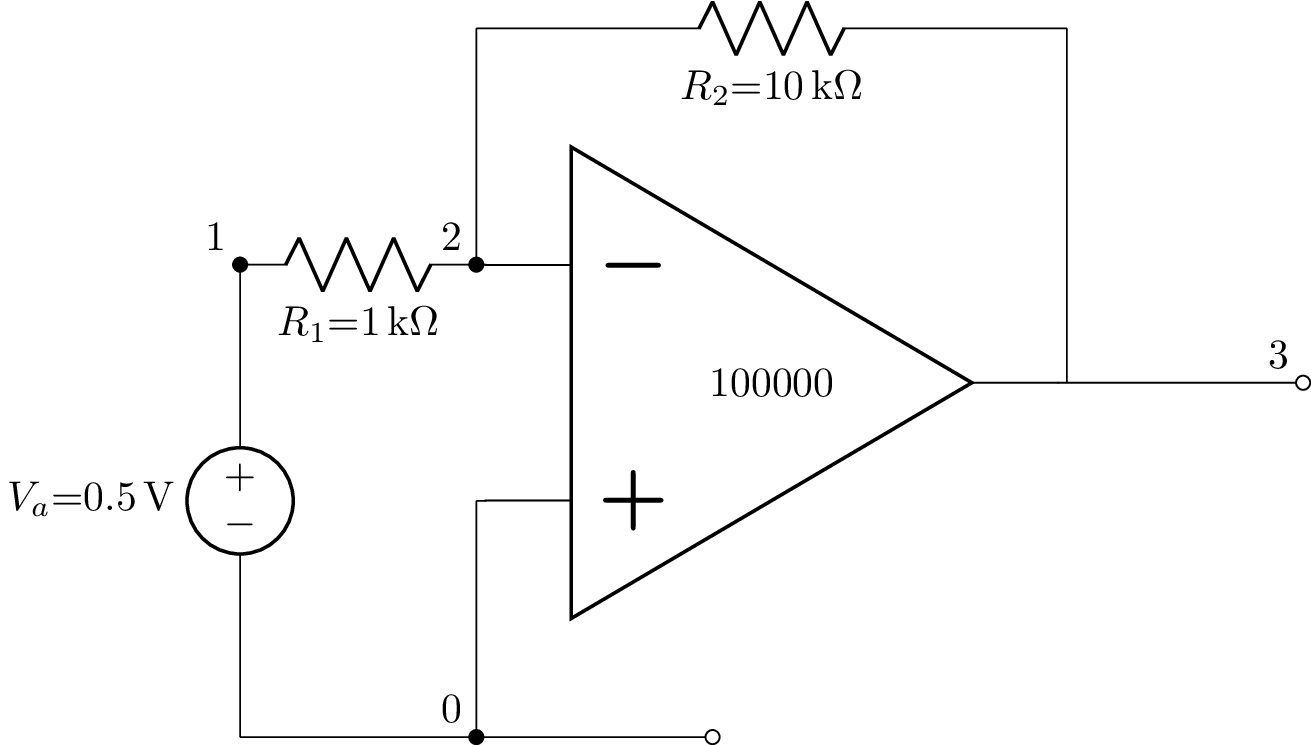

In [78]:
#CIRCUITO INVERSOR CON VALORES NUMERICOS (A = 1e5)
ejemplo = Circuit("""
                Va 1 0_1 0.5; down
                R1 1 2 1000; right
                R2 2_1 3_1 10000; right
                E1 3_2 0_3 opamp 2_0 2 1e5; mirror
                W 0_1 0; right
                W 2_0 0; down
                W 3_2 3; right
                W 0 0_3; right
                W 2_1 2; down
                W 3_1 3_2; down
            """)
ejemplo.draw()

In [79]:
#RESULTADOS: salida Vo, nodo 2 (masa virtual) y corriente por R1
float(ejemplo[3].V.dc.expr), float(ejemplo[2].V.dc.expr), float(ejemplo['R1'].I.dc.expr)